## Create Spillway Particle Time Series (Selected Years)

This notebook builds particle-release time series from the updated BCS leakage discharge CSV, using only days with positive discharge and only the selected years.

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

### 1. Configuration

Set which years to run and particle scaling settings.

In [39]:
PROJECT_ROOT = Path.cwd().parent
DISCHARGE_CSV_PATH = PROJECT_ROOT / 'outputs' / 'bcs' / 'bcs_leakage_discharge_2000_June2026.csv'

# Select calendar years from the discharge date column
SELECTED_YEARS = [2013]

SMOOTH_DAYS = 3
SCALE_FACTOR = 0.2
FONTSIZE = 8

# Output locations
OUT_NOTEBOOK_DATA = PROJECT_ROOT / 'outputs' / 'dorado' / 'from_spillway' / 'bcs_particles_selected_years.csv'
OUT_NOTEBOOK_DATA.parent.mkdir(parents=True, exist_ok=True)

print('Input discharge CSV:', DISCHARGE_CSV_PATH)
print('Selected years:', SELECTED_YEARS)
print('Scale factor:', SCALE_FACTOR)

Input discharge CSV: c:\Users\hydro\Lake_Pontchartrain_Model\outputs\bcs\bcs_leakage_discharge_2000_June2026.csv
Selected years: [2013]
Scale factor: 0.2


### 2. Load Updated BCS Discharge CSV

In [40]:
if not DISCHARGE_CSV_PATH.exists():
    raise FileNotFoundError(f'Discharge CSV not found: {DISCHARGE_CSV_PATH}')

df = pd.read_csv(DISCHARGE_CSV_PATH)

required_cols = {'date', 'discharge'}
missing_cols = required_cols - set(df.columns)
if missing_cols:
    raise ValueError(f'Missing required columns in discharge CSV: {sorted(missing_cols)}')

df['date'] = pd.to_datetime(df['date'])
df['discharge'] = pd.to_numeric(df['discharge'], errors='coerce').fillna(0.0)
df['year'] = df['date'].dt.year

available_years = sorted(df['year'].dropna().astype(int).unique().tolist())
print('Available years in CSV:', available_years)
print('Rows in discharge file:', len(df))

Available years in CSV: [2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Rows in discharge file: 9671


### 3. Build Spillway-Only Particle Series for Selected Years

For each selected calendar year, keep only discharge > 0 days, then apply smoothing and scaling.

In [41]:
selected_years = [int(y) for y in SELECTED_YEARS]
missing_years = [y for y in selected_years if y not in available_years]
if missing_years:
    raise ValueError(f'Selected years not found in discharge CSV: {missing_years}')

frames = []
for y in selected_years:
    tmp = df.loc[df['year'] == y, ['date', 'discharge']].copy()
    tmp = tmp.rename(columns={'discharge': 'Q_flow'})

    # Spillway-only: keep days with positive discharge
    tmp = tmp[tmp['Q_flow'] > 0].copy()
    if tmp.empty:
        print(f'Skipping {y}: no positive-discharge days')
        continue

    tmp['Q_smooth'] = tmp['Q_flow'].rolling(window=SMOOTH_DAYS, center=True, min_periods=1).mean()
    tmp['Q_particles'] = np.round(tmp['Q_smooth']).astype(int)
    tmp.loc[tmp['Q_particles'] < 0, 'Q_particles'] = 0

    tmp['Q_particles_scaled'] = np.round(tmp['Q_particles'] * SCALE_FACTOR).astype(int)
    tmp.loc[tmp['Q_particles_scaled'] < 0, 'Q_particles_scaled'] = 0

    tmp['year_column'] = f'year{y}'
    tmp['year_label'] = str(y)
    frames.append(tmp)

if not frames:
    raise ValueError('No spillway data generated for the selected years.')

spillway_particles = pd.concat(frames, ignore_index=True)
spillway_particles = spillway_particles.sort_values(['year_label', 'date']).reset_index(drop=True)

print('Generated rows:', len(spillway_particles))
spillway_particles.head()

Generated rows: 65


,date,Q_flow,Q_smooth,Q_particles,Q_particles_scaled,year_column,year_label
0,2013-01-30,0.852,1.258500,1,0,year2013,2013
1,2013-04-28,1.665,3.274000,3,1,year2013,2013
2,2013-04-29,7.305,7.298333,7,1,year2013,2013
3,2013-04-30,12.925,14.822000,15,3,year2013,2013
4,2013-05-01,24.236,22.583000,23,5,year2013,2013


### 4. Summary Stats

In [42]:
stats = (spillway_particles.groupby('year_label')
         .agg(open_days=('date', 'count'),
              min_particles=('Q_particles_scaled', 'min'),
              max_particles=('Q_particles_scaled', 'max'),
              total_particles=('Q_particles_scaled', 'sum'))
         .reset_index())
stats

,year_label,open_days,min_particles,max_particles,total_particles
0,2013,65,0,25,651


### 5. Plot Scaled Particles

One panel per selected year.

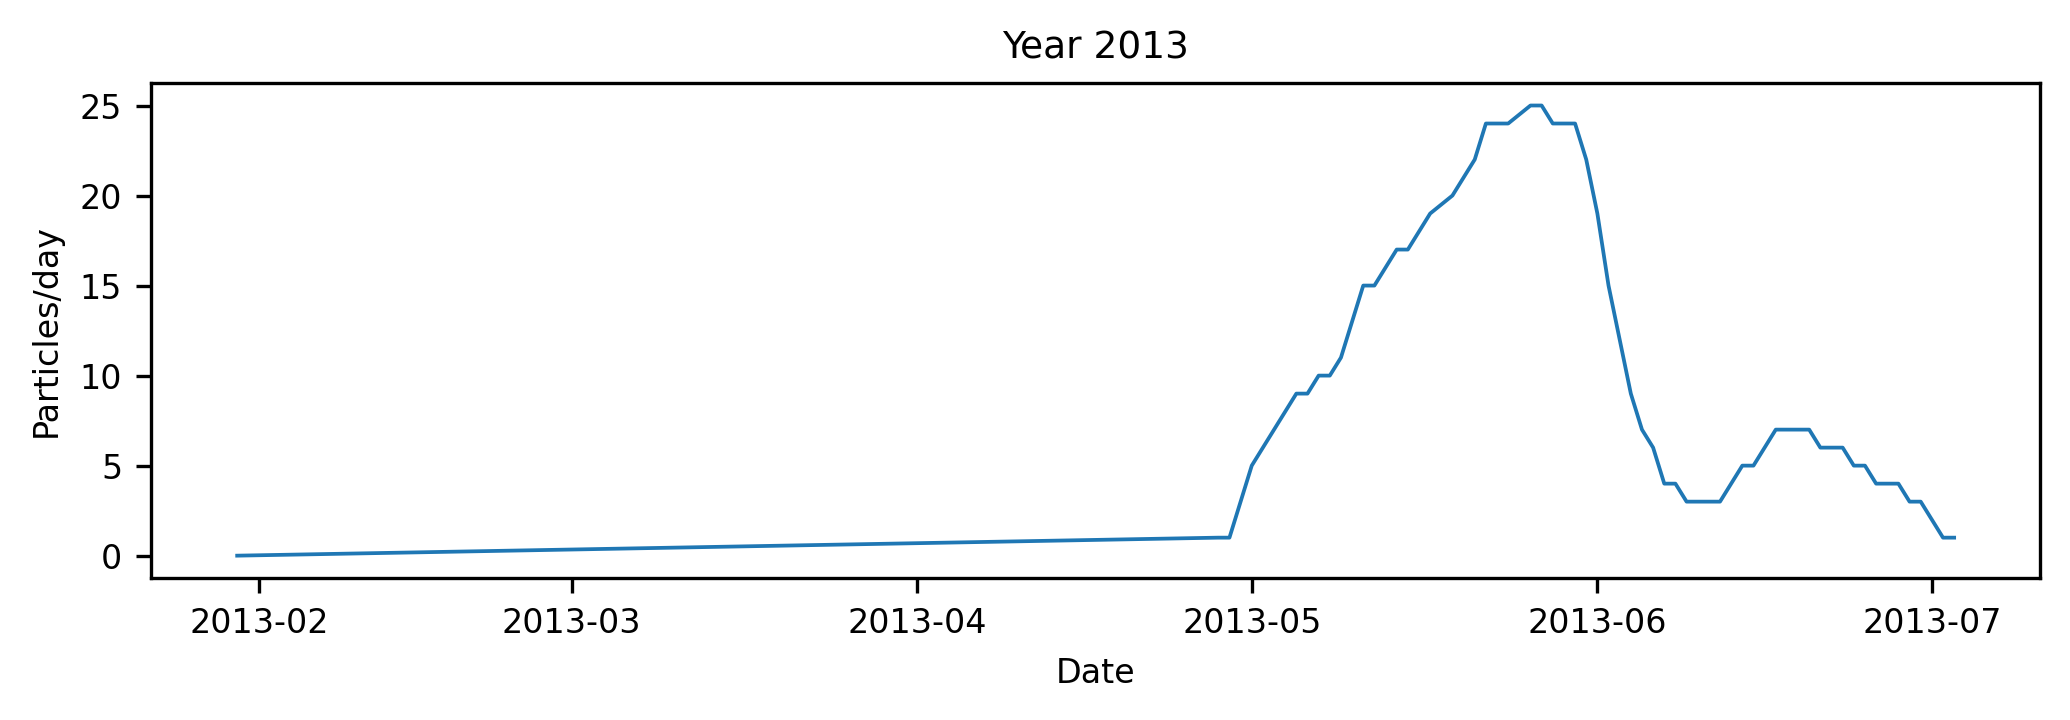

In [43]:
years = stats['year_label'].tolist()
n = len(years)
fig, axes = plt.subplots(n, 1, figsize=(7, max(2.5, 2.2 * n)), dpi=300, sharex=False)
if n == 1:
    axes = [axes]

for ax, y in zip(axes, years):
    sub = spillway_particles[spillway_particles['year_label'] == y]
    ax.plot(sub['date'], sub['Q_particles_scaled'], linewidth=0.9)
    ax.set_title(f'Year {y}', fontsize=FONTSIZE + 1)
    ax.set_ylabel('Particles/day', fontsize=FONTSIZE)
    ax.tick_params(axis='both', labelsize=FONTSIZE)

axes[-1].set_xlabel('Date', fontsize=FONTSIZE)
plt.tight_layout()
plt.show()

### 6. Save Yearly Outputs

Write one CSV per year with only datetime and particle_number columns.

In [44]:
OUT_YEARLY_DIR = PROJECT_ROOT / 'outputs' / 'dorado' / 'from_spillway'
OUT_YEARLY_DIR.mkdir(parents=True, exist_ok=True)

saved_files = []
for y in spillway_particles['year_label'].unique():
    out_year = OUT_YEARLY_DIR / f'bcs_{y}_particles.csv'
    out_df = (spillway_particles.loc[spillway_particles['year_label'] == y, ['date', 'Q_particles_scaled']]
              .rename(columns={'date': 'datetime', 'Q_particles_scaled': 'particle_number'})
              .reset_index(drop=True))
    out_df.to_csv(out_year, index=False)
    saved_files.append(out_year)

print('Saved yearly files:')
for f in saved_files:
    print(f)

Saved yearly files:
c:\Users\hydro\Lake_Pontchartrain_Model\outputs\dorado\from_spillway\bcs_2013_particles.csv
